<a href="https://colab.research.google.com/github/binh-ng/african-fracture-eda/blob/main/african-fracture-eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AFRICAN MEDICAL MULTIMODAL FRACTURE DATASET - EXPLORATORY DATA ANALYSIS

[1/10] Fetching data from HuggingFace...
✓ Data loaded successfully! Shape: (1129, 40)
  - Records: 1129
  - Features: 40

[2/10] Generating data overview...

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1129 entries, 0 to 1128
Data columns (total 40 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   record_id                  1129 non-null   object 
 1   patient_id                 1129 non-null   object 
 2   fracture_type              1129 non-null   object 
 3   age                        1129 non-null   int64  
 4   gender                     1129 non-null   object 
 5   country                    1129 non-null   object 
 6   region_type                1129 non-null   object 
 7   occupation                 1129 non-null   object 
 8   education_level            1129 non-null   object 
 9   healthcare_distance_km    

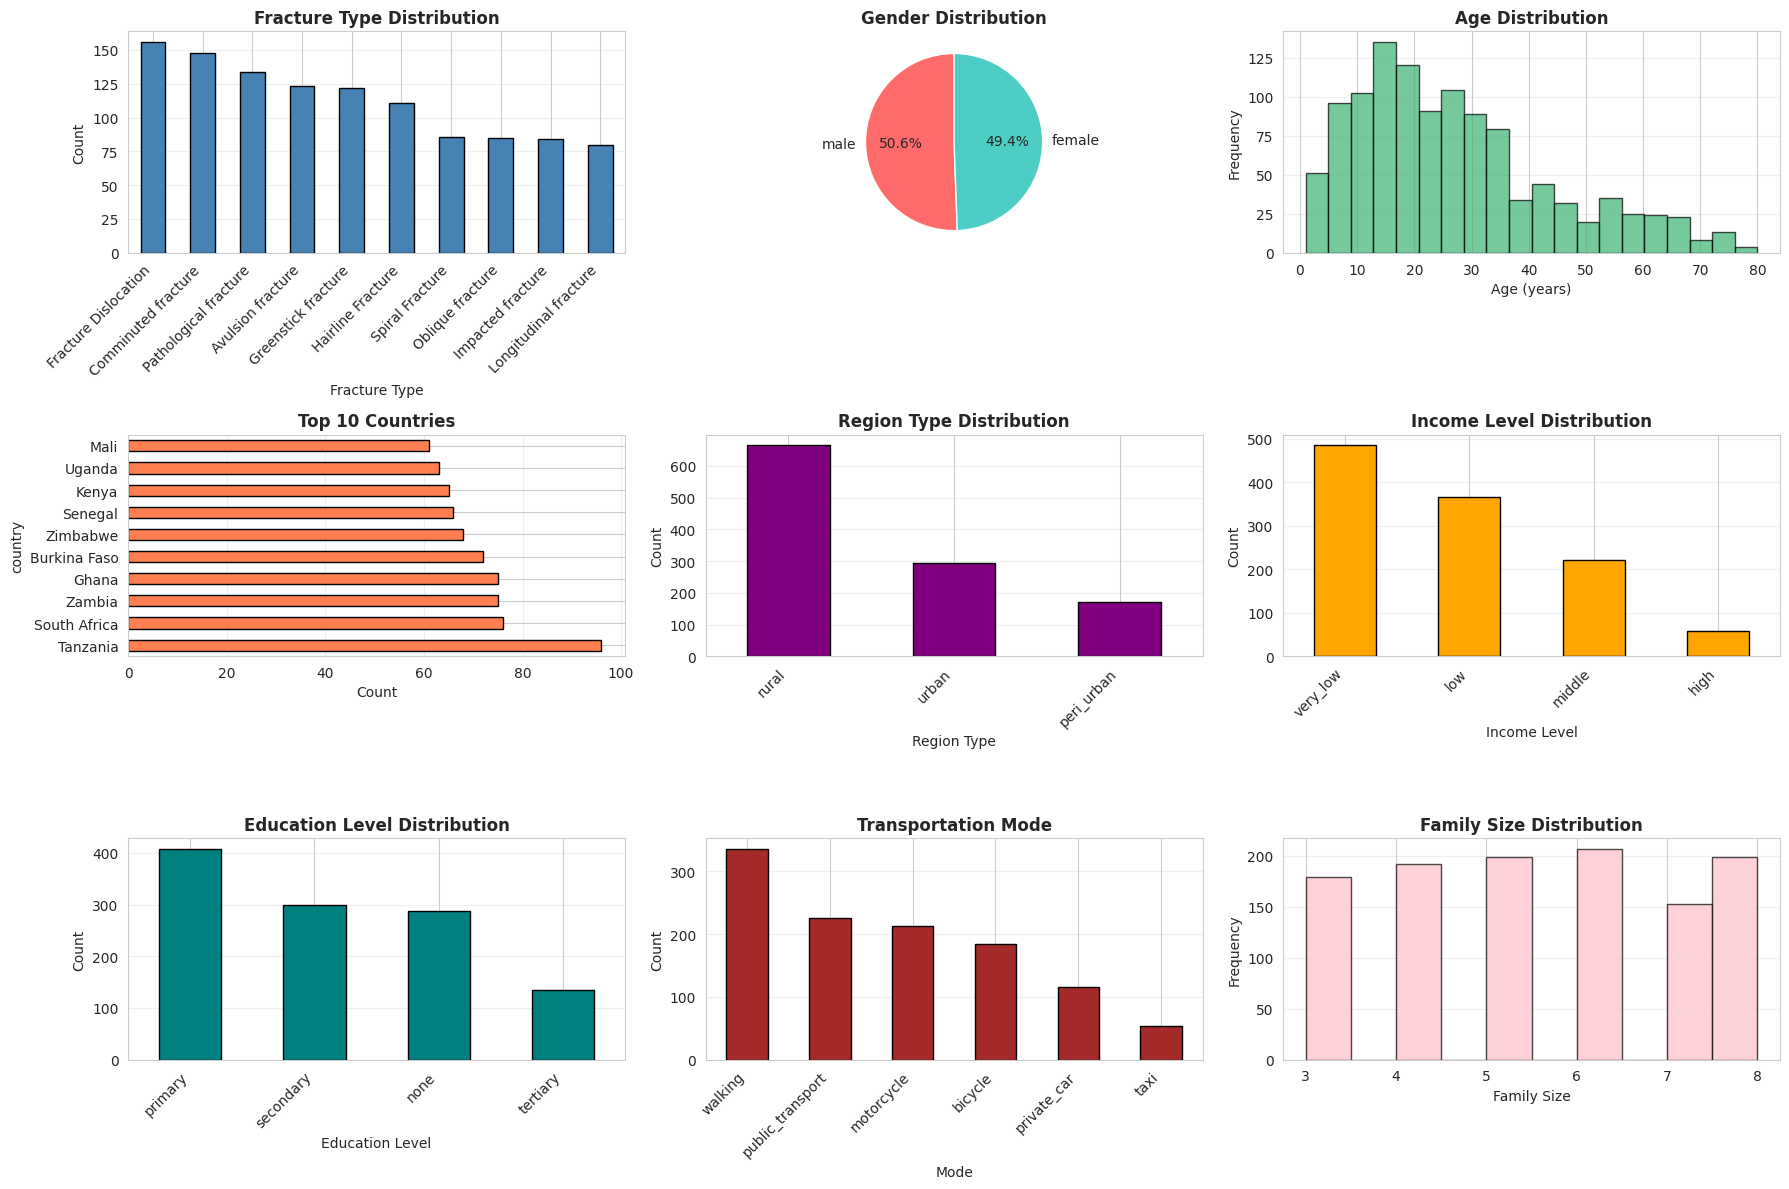


[7/10] Creating clinical measurement visualizations...
✓ Saved: 02_clinical_measurements.png


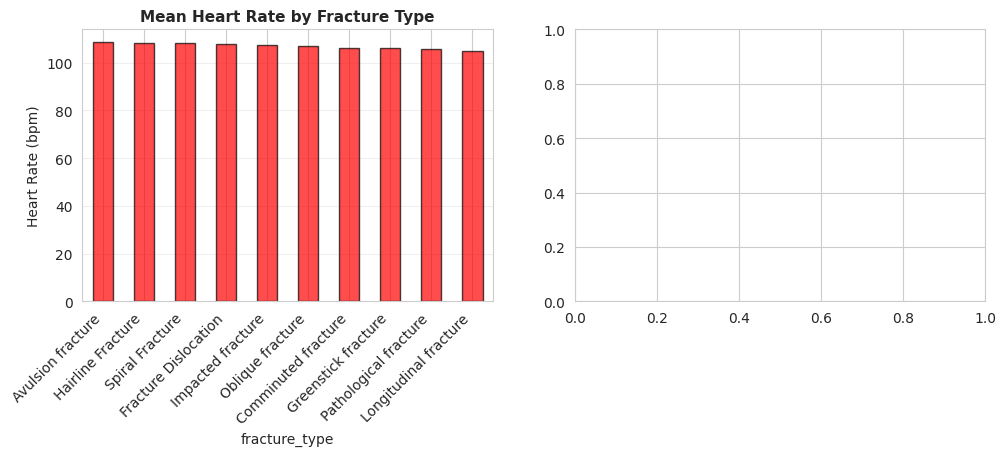

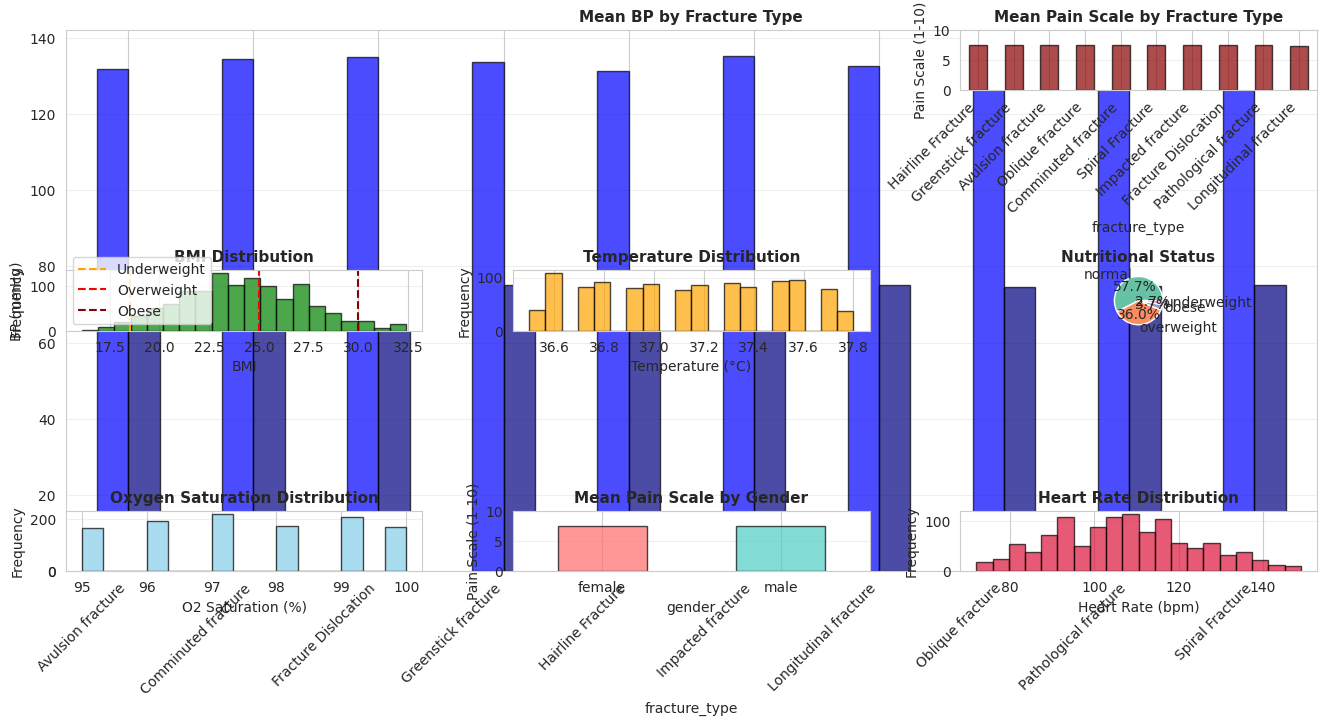


[8/10] Creating box plots...
✓ Saved: 03_clinical_boxplots.png


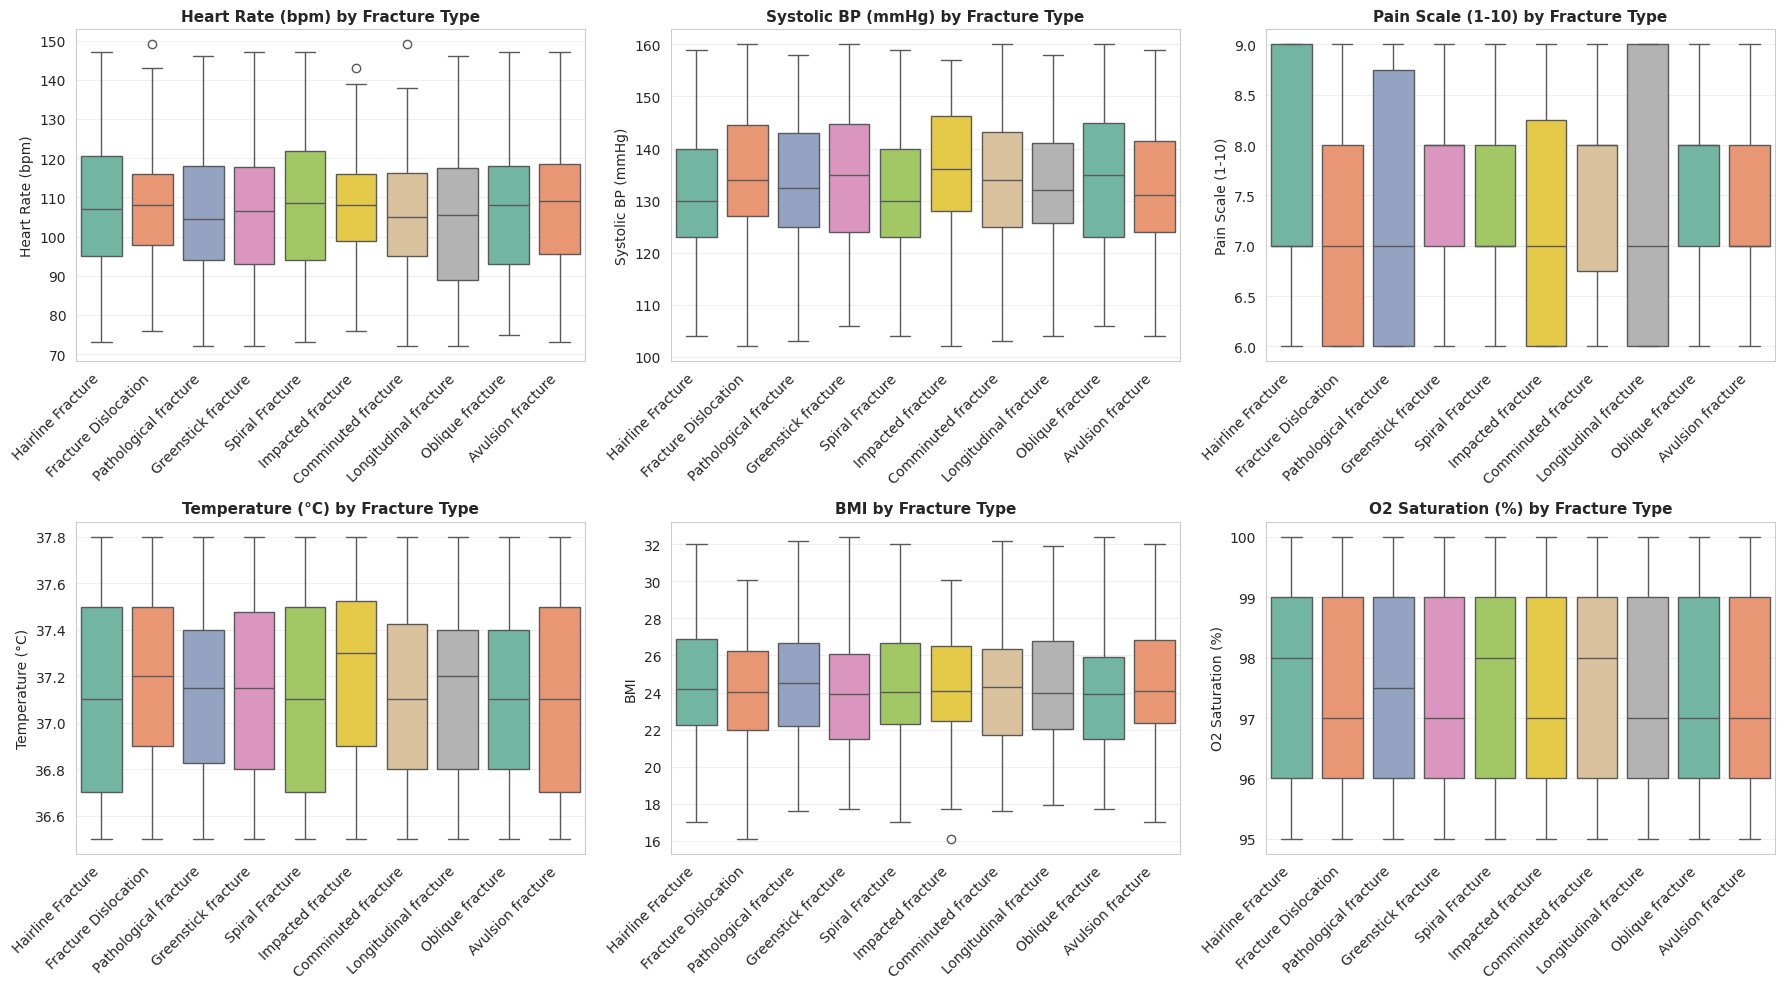


[9/10] Analyzing correlations...
✓ Saved: 04_correlation_heatmap.png


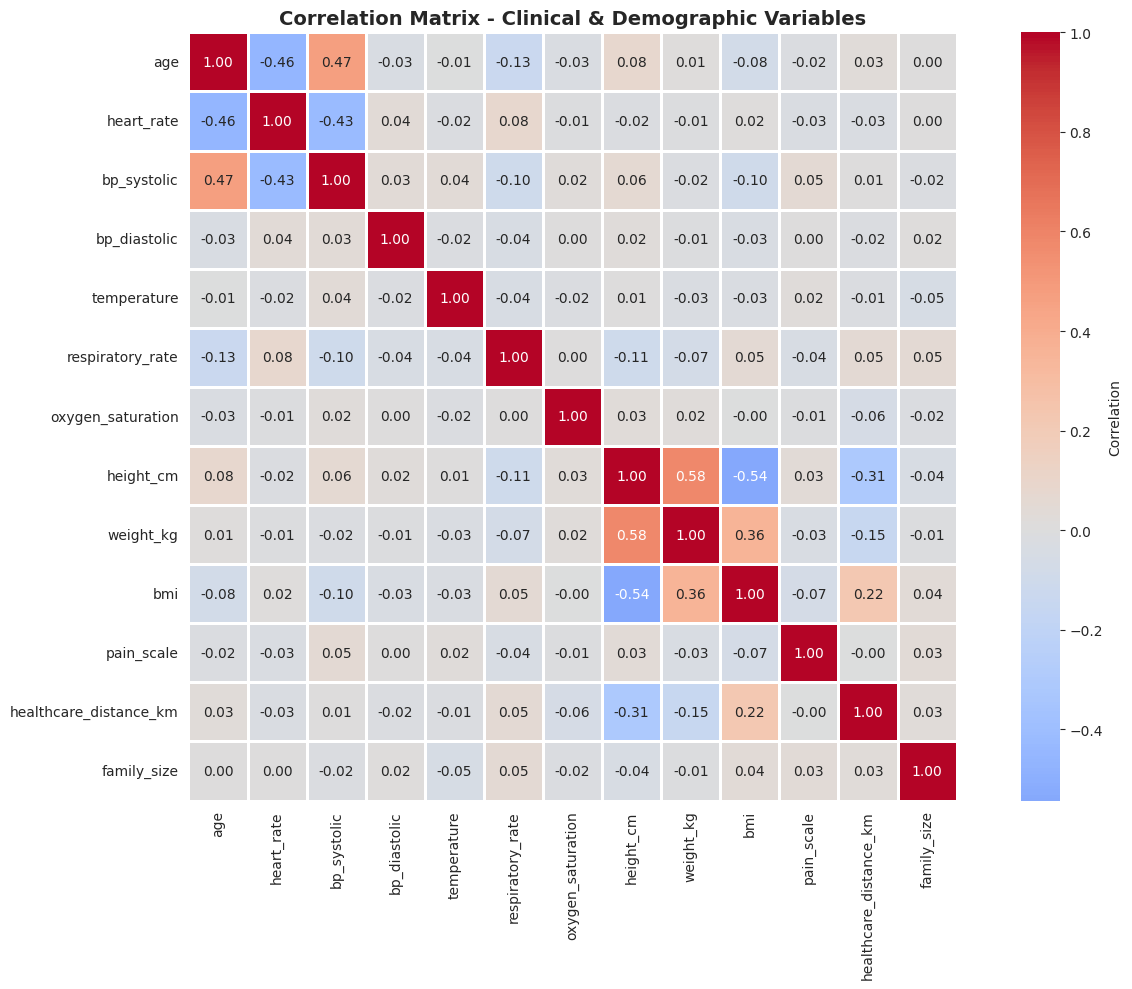


Top 10 Strongest Correlations (excluding self-correlations):
  height_cm <-> weight_kg: 0.583
  height_cm <-> bmi: -0.543
  age <-> bp_systolic: 0.472
  age <-> heart_rate: -0.458
  heart_rate <-> bp_systolic: -0.425
  weight_kg <-> bmi: 0.357
  height_cm <-> healthcare_distance_km: -0.311
  bmi <-> healthcare_distance_km: 0.219
  weight_kg <-> healthcare_distance_km: -0.147
  age <-> respiratory_rate: -0.134

[10/10] Creating relationship scatter plots...
✓ Saved: 05_relationships.png


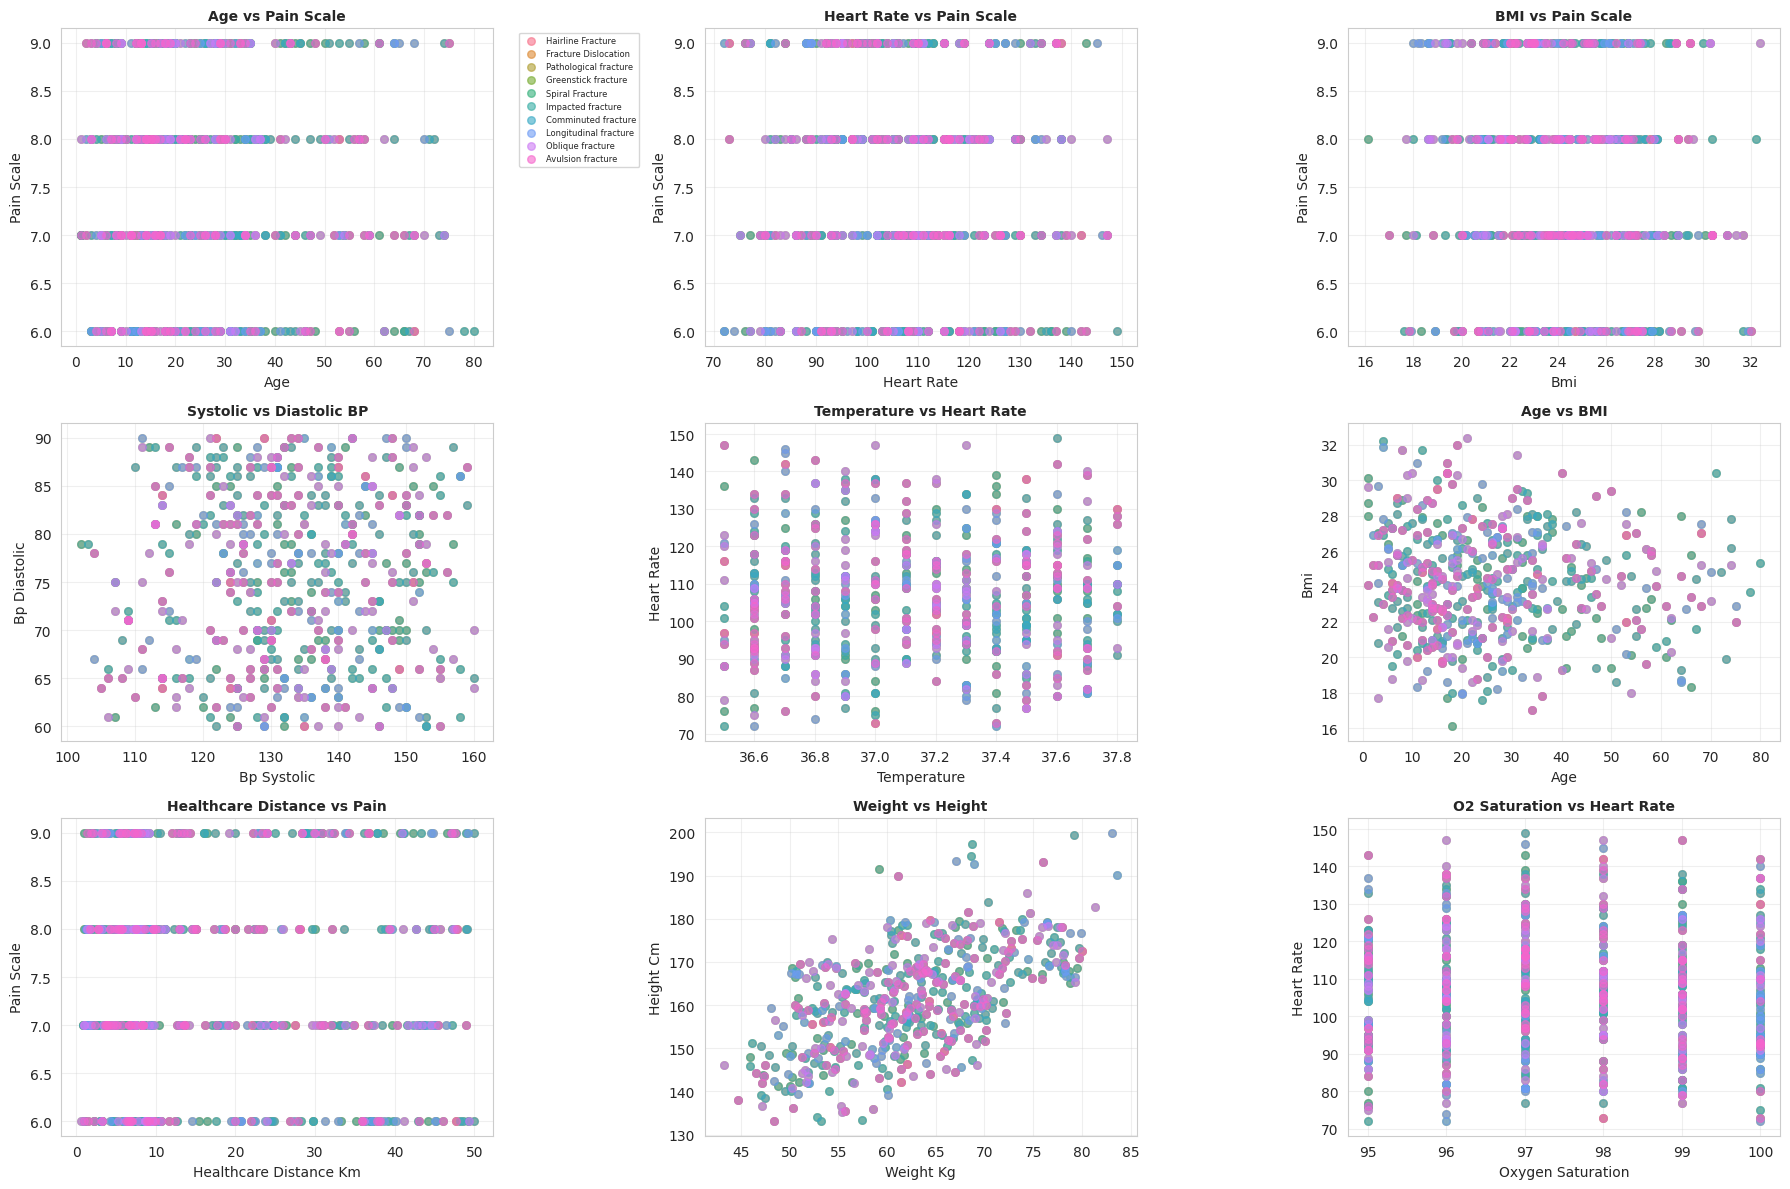


ADDITIONAL INSIGHTS

Mechanism of Injury by Fracture Type:
fracture_type                      Avulsion fracture  Comminuted fracture  \
mechanism_of_injury                                                         
animal_attack                                      4                    3   
assault                                            6                   10   
domestic_accident                                 12                   12   
fall_from_height                                  30                   30   
road_traffic_accident                             37                   57   
sports_injury                                     10                   13   
traditional_medicine_complication                  2                    3   
workplace_injury                                  22                   20   

fracture_type                      Fracture Dislocation  Greenstick fracture  \
mechanism_of_injury                                                            
animal_at

In [20]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import json
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

print("="*80)
print("AFRICAN MEDICAL MULTIMODAL FRACTURE DATASET - EXPLORATORY DATA ANALYSIS")
print("="*80)

# ========================================
# 1. FETCH AND LOAD DATA
# ========================================
print("\n[1/10] Fetching data from HuggingFace...")
url = "https://huggingface.co/datasets/electricsheepafrica/african-medical-multimodal-fracture/raw/main/data/multimodal_records.json"

response = requests.get(url)
data = json.loads(response.text)

# Flatten nested JSON structure
records = []
for record in data:
    flat_record = {
        'record_id': record['record_id'],
        'patient_id': record['patient_id'],
        'fracture_type': record['fracture_type'],

        # Demographics
        'age': record['demographics']['age'],
        'gender': record['demographics']['gender'],
        'country': record['demographics']['country'],
        'region_type': record['demographics']['region_type'],
        'occupation': record['demographics']['occupation'],
        'education_level': record['demographics']['education_level'],
        'healthcare_distance_km': record['demographics']['healthcare_distance_km'],
        'transportation_mode': record['demographics']['transportation_mode'],
        'income_level': record['demographics']['income_level'],
        'insurance_status': record['demographics']['insurance_status'],
        'family_size': record['demographics']['family_size'],
        'primary_language': record['demographics']['primary_language'],

        # Clinical Text
        'mechanism_of_injury': record['clinical_text']['mechanism_of_injury'],
        'pain_intensity': record['clinical_text']['pain_description']['intensity'],
        'pain_quality': record['clinical_text']['pain_description']['quality'],
        'used_traditional_medicine': record['clinical_text']['traditional_medicine_history']['used_traditional_medicine'],
        'cultural_beliefs': record['clinical_text']['cultural_context']['cultural_beliefs_about_injury'],
        'preferred_treatment': record['clinical_text']['cultural_context']['preferred_treatment_approach'],

        # Clinical Measurements
        'heart_rate': record['clinical_measurements']['vital_signs']['heart_rate'],
        'bp_systolic': record['clinical_measurements']['vital_signs']['blood_pressure_systolic'],
        'bp_diastolic': record['clinical_measurements']['vital_signs']['blood_pressure_diastolic'],
        'temperature': record['clinical_measurements']['vital_signs']['temperature'],
        'respiratory_rate': record['clinical_measurements']['vital_signs']['respiratory_rate'],
        'oxygen_saturation': record['clinical_measurements']['vital_signs']['oxygen_saturation'],
        'height_cm': record['clinical_measurements']['anthropometric']['height_cm'],
        'weight_kg': record['clinical_measurements']['anthropometric']['weight_kg'],
        'bmi': record['clinical_measurements']['anthropometric']['bmi'],
        'pain_scale': record['clinical_measurements']['pain_assessment']['pain_scale_1_10'],
        'nutritional_status': record['clinical_measurements']['nutritional_status'],

        # Environmental Context
        'season': record['environmental_context']['season'],
        'injury_time': record['environmental_context']['injury_time'],
        'day_of_week': record['environmental_context']['day_of_week'],
        'precipitation': record['environmental_context']['weather_conditions']['precipitation'],
        'visibility': record['environmental_context']['weather_conditions']['visibility'],

        # Mobile Health
        'owns_phone': record['mobile_health_data']['phone_ownership']['owns_phone'],
        'phone_type': record['mobile_health_data']['phone_ownership'].get('phone_type', 'none'),
        'digital_literacy': record['mobile_health_data']['digital_literacy'],
    }
    records.append(flat_record)

df = pd.DataFrame(records)
print(f"✓ Data loaded successfully! Shape: {df.shape}")
print(f"  - Records: {len(df)}")
print(f"  - Features: {len(df.columns)}")

# ========================================
# 2. DATA OVERVIEW
# ========================================
print("\n[2/10] Generating data overview...")
print("\nDataset Info:")
print(df.info())

print("\nFirst 3 records:")
print(df.head(3))

print("\nMissing Values:")
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("No missing values found!")

print("\nBasic Statistics:")
print(df.describe())

# ========================================
# 3. DEMOGRAPHIC ANALYSIS
# ========================================
print("\n[3/10] Analyzing demographics...")

print(f"\nUnique Countries: {df['country'].nunique()}")
print(f"Most common country: {df['country'].value_counts().index[0]} ({df['country'].value_counts().values[0]} cases)")

print(f"\nGender Distribution:")
print(df['gender'].value_counts())

print(f"\nAge Statistics:")
print(f"  Mean: {df['age'].mean():.1f} years")
print(f"  Median: {df['age'].median():.1f} years")
print(f"  Range: {df['age'].min()}-{df['age'].max()} years")

print(f"\nRegion Types:")
print(df['region_type'].value_counts())

print(f"\nEducation Levels:")
print(df['education_level'].value_counts())

print(f"\nIncome Levels:")
print(df['income_level'].value_counts())

# ========================================
# 4. FRACTURE TYPE ANALYSIS
# ========================================
print("\n[4/10] Analyzing fracture types...")

print(f"\nFracture Type Distribution:")
fracture_counts = df['fracture_type'].value_counts()
print(fracture_counts)

print(f"\nMechanism of Injury:")
print(df['mechanism_of_injury'].value_counts())

print(f"\nTraditional Medicine Usage:")
print(f"Used: {df['used_traditional_medicine'].sum()} ({df['used_traditional_medicine'].sum()/len(df)*100:.1f}%)")
print(f"Not Used: {(~df['used_traditional_medicine']).sum()} ({(~df['used_traditional_medicine']).sum()/len(df)*100:.1f}%)")

# ========================================
# 5. CLINICAL MEASUREMENTS SUMMARY
# ========================================
print("\n[5/10] Summarizing clinical measurements...")

clinical_vars = ['heart_rate', 'bp_systolic', 'bp_diastolic', 'temperature',
                 'respiratory_rate', 'oxygen_saturation', 'pain_scale', 'bmi']

print("\nClinical Measurements Summary:")
for var in clinical_vars:
    print(f"\n{var.upper()}:")
    print(f"  Mean: {df[var].mean():.2f}")
    print(f"  Std: {df[var].std():.2f}")
    print(f"  Range: {df[var].min():.2f} - {df[var].max():.2f}")

print("\nNutritional Status Distribution:")
print(df['nutritional_status'].value_counts())

# ========================================
# 6. VISUALIZATIONS - DEMOGRAPHICS
# ========================================
print("\n[6/10] Creating demographic visualizations...")

fig = plt.figure(figsize=(18, 12))

# Fracture type distribution
plt.subplot(3, 3, 1)
fracture_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Fracture Type Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Fracture Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Gender distribution
plt.subplot(3, 3, 2)
df['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                  colors=['#FF6B6B', '#4ECDC4'], startangle=90)
plt.title('Gender Distribution', fontweight='bold', fontsize=12)
plt.ylabel('')

# Age distribution
plt.subplot(3, 3, 3)
plt.hist(df['age'], bins=20, color='mediumseagreen', edgecolor='black', alpha=0.7)
plt.title('Age Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Age (years)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

# Top 10 countries
plt.subplot(3, 3, 4)
top_countries = df['country'].value_counts().head(10)
top_countries.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Top 10 Countries', fontweight='bold', fontsize=12)
plt.xlabel('Count')
plt.grid(axis='x', alpha=0.3)

# Region type
plt.subplot(3, 3, 5)
df['region_type'].value_counts().plot(kind='bar', color='purple', edgecolor='black')
plt.title('Region Type Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Region Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Income level
plt.subplot(3, 3, 6)
df['income_level'].value_counts().plot(kind='bar', color='orange', edgecolor='black')
plt.title('Income Level Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Income Level')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Education level
plt.subplot(3, 3, 7)
df['education_level'].value_counts().plot(kind='bar', color='teal', edgecolor='black')
plt.title('Education Level Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Transportation mode
plt.subplot(3, 3, 8)
df['transportation_mode'].value_counts().plot(kind='bar', color='brown', edgecolor='black')
plt.title('Transportation Mode', fontweight='bold', fontsize=12)
plt.xlabel('Mode')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Family size
plt.subplot(3, 3, 9)
plt.hist(df['family_size'], bins=10, color='pink', edgecolor='black', alpha=0.7)
plt.title('Family Size Distribution', fontweight='bold', fontsize=12)
plt.xlabel('Family Size')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('01_demographics.png', dpi=300, bbox_inches='tight')
print("✓ Saved: 01_demographics.png")
plt.show()

# ========================================
# 7. VISUALIZATIONS - CLINICAL MEASUREMENTS
# ========================================
print("\n[7/10] Creating clinical measurement visualizations...")

fig = plt.figure(figsize=(18, 12))

# Heart rate by fracture type
plt.subplot(3, 3, 1)
fracture_hr = df.groupby('fracture_type')['heart_rate'].mean().sort_values(ascending=False)
fracture_hr.plot(kind='bar', color='red', edgecolor='black', alpha=0.7)
plt.title('Mean Heart Rate by Fracture Type', fontweight='bold', fontsize=11)
plt.ylabel('Heart Rate (bpm)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Blood pressure by fracture type
plt.subplot(3, 3, 2)
fracture_bp = df.groupby('fracture_type')[['bp_systolic', 'bp_diastolic']].mean()
fracture_bp.plot(kind='bar', color=['blue', 'navy'], edgecolor='black', alpha=0.7)
plt.title('Mean BP by Fracture Type', fontweight='bold', fontsize=11)
plt.ylabel('BP (mmHg)')
plt.xticks(rotation=45, ha='right')
plt.legend(['Systolic', 'Diastolic'])
plt.grid(axis='y', alpha=0.3)

# Pain scale by fracture type
plt.subplot(3, 3, 3)
fracture_pain = df.groupby('fracture_type')['pain_scale'].mean().sort_values(ascending=False)
fracture_pain.plot(kind='bar', color='darkred', edgecolor='black', alpha=0.7)
plt.title('Mean Pain Scale by Fracture Type', fontweight='bold', fontsize=11)
plt.ylabel('Pain Scale (1-10)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 10)
plt.grid(axis='y', alpha=0.3)

# BMI distribution
plt.subplot(3, 3, 4)
plt.hist(df['bmi'], bins=20, color='green', edgecolor='black', alpha=0.7)
plt.title('BMI Distribution', fontweight='bold', fontsize=11)
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.axvline(18.5, color='orange', linestyle='--', label='Underweight')
plt.axvline(25, color='red', linestyle='--', label='Overweight')
plt.axvline(30, color='darkred', linestyle='--', label='Obese')
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Temperature distribution
plt.subplot(3, 3, 5)
plt.hist(df['temperature'], bins=20, color='orange', edgecolor='black', alpha=0.7)
plt.title('Temperature Distribution', fontweight='bold', fontsize=11)
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

# Nutritional status
plt.subplot(3, 3, 6)
df['nutritional_status'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                              colors=sns.color_palette('Set2'))
plt.title('Nutritional Status', fontweight='bold', fontsize=11)
plt.ylabel('')

# Oxygen saturation
plt.subplot(3, 3, 7)
plt.hist(df['oxygen_saturation'], bins=15, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Oxygen Saturation Distribution', fontweight='bold', fontsize=11)
plt.xlabel('O2 Saturation (%)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

# Pain intensity by gender
plt.subplot(3, 3, 8)
df.groupby('gender')['pain_scale'].mean().plot(kind='bar', color=['#FF6B6B', '#4ECDC4'],
                                                 edgecolor='black', alpha=0.7)
plt.title('Mean Pain Scale by Gender', fontweight='bold', fontsize=11)
plt.ylabel('Pain Scale (1-10)')
plt.xticks(rotation=0)
plt.ylim(0, 10)
plt.grid(axis='y', alpha=0.3)

# Heart rate distribution
plt.subplot(3, 3, 9)
plt.hist(df['heart_rate'], bins=20, color='crimson', edgecolor='black', alpha=0.7)
plt.title('Heart Rate Distribution', fontweight='bold', fontsize=11)
plt.xlabel('Heart Rate (bpm)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('02_clinical_measurements.png', dpi=300, bbox_inches='tight')
print("✓ Saved: 02_clinical_measurements.png")
plt.show()

# ========================================
# 8. BOX PLOTS - CLINICAL BY FRACTURE TYPE
# ========================================
print("\n[8/10] Creating box plots...")

fig = plt.figure(figsize=(18, 10))

clinical_metrics = [
    ('heart_rate', 'Heart Rate (bpm)', 'red'),
    ('bp_systolic', 'Systolic BP (mmHg)', 'blue'),
    ('pain_scale', 'Pain Scale (1-10)', 'darkred'),
    ('temperature', 'Temperature (°C)', 'orange'),
    ('bmi', 'BMI', 'green'),
    ('oxygen_saturation', 'O2 Saturation (%)', 'skyblue')
]

for idx, (metric, label, color) in enumerate(clinical_metrics, 1):
    plt.subplot(2, 3, idx)
    sns.boxplot(data=df, x='fracture_type', y=metric, palette='Set2')
    plt.title(f'{label} by Fracture Type', fontweight='bold', fontsize=11)
    plt.xlabel('')
    plt.ylabel(label)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('03_clinical_boxplots.png', dpi=300, bbox_inches='tight')
print("✓ Saved: 03_clinical_boxplots.png")
plt.show()

# ========================================
# 9. CORRELATION ANALYSIS
# ========================================
print("\n[9/10] Analyzing correlations...")

# Select numeric columns for correlation
numeric_cols = ['age', 'heart_rate', 'bp_systolic', 'bp_diastolic',
                'temperature', 'respiratory_rate', 'oxygen_saturation',
                'height_cm', 'weight_kg', 'bmi', 'pain_scale',
                'healthcare_distance_km', 'family_size']

corr_matrix = df[numeric_cols].corr()

# Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, fmt='.2f', cbar_kws={'label': 'Correlation'})
plt.title('Correlation Matrix - Clinical & Demographic Variables',
          fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('04_correlation_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ Saved: 04_correlation_heatmap.png")
plt.show()

print("\nTop 10 Strongest Correlations (excluding self-correlations):")
corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_pairs.append((corr_matrix.columns[i],
                          corr_matrix.columns[j],
                          corr_matrix.iloc[i, j]))
corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for var1, var2, corr in corr_pairs[:10]:
    print(f"  {var1} <-> {var2}: {corr:.3f}")

# ========================================
# 10. SCATTER PLOTS - RELATIONSHIPS
# ========================================
print("\n[10/10] Creating relationship scatter plots...")

fig = plt.figure(figsize=(18, 12))

scatter_configs = [
    ('age', 'pain_scale', 'Age vs Pain Scale'),
    ('heart_rate', 'pain_scale', 'Heart Rate vs Pain Scale'),
    ('bmi', 'pain_scale', 'BMI vs Pain Scale'),
    ('bp_systolic', 'bp_diastolic', 'Systolic vs Diastolic BP'),
    ('temperature', 'heart_rate', 'Temperature vs Heart Rate'),
    ('age', 'bmi', 'Age vs BMI'),
    ('healthcare_distance_km', 'pain_scale', 'Healthcare Distance vs Pain'),
    ('weight_kg', 'height_cm', 'Weight vs Height'),
    ('oxygen_saturation', 'heart_rate', 'O2 Saturation vs Heart Rate')
]

for idx, (x_var, y_var, title) in enumerate(scatter_configs, 1):
    plt.subplot(3, 3, idx)

    # Color by fracture type
    fracture_types = df['fracture_type'].unique()
    colors = sns.color_palette('husl', len(fracture_types))

    for ft, color in zip(fracture_types, colors):
        mask = df['fracture_type'] == ft
        plt.scatter(df[mask][x_var], df[mask][y_var],
                   alpha=0.6, s=30, label=ft, color=color)

    plt.xlabel(x_var.replace('_', ' ').title())
    plt.ylabel(y_var.replace('_', ' ').title())
    plt.title(title, fontweight='bold', fontsize=10)
    if idx == 1:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6)
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('05_relationships.png', dpi=300, bbox_inches='tight')
print("✓ Saved: 05_relationships.png")
plt.show()

# ========================================
# 11. ADDITIONAL ANALYSIS
# ========================================
print("\n" + "="*80)
print("ADDITIONAL INSIGHTS")
print("="*80)

# Mechanism of injury vs fracture type
print("\nMechanism of Injury by Fracture Type:")
mechanism_fracture = pd.crosstab(df['mechanism_of_injury'], df['fracture_type'])
print(mechanism_fracture)

# Traditional medicine usage by country
print("\nTraditional Medicine Usage by Country (Top 10):")
trad_med_country = df.groupby('country')['used_traditional_medicine'].agg(['sum', 'count'])
trad_med_country['percentage'] = (trad_med_country['sum'] / trad_med_country['count'] * 100).round(1)
print(trad_med_country.sort_values('sum', ascending=False).head(10))

# Pain scale by region type
print("\nMean Pain Scale by Region Type:")
print(df.groupby('region_type')['pain_scale'].agg(['mean', 'std', 'min', 'max']).round(2))

# Healthcare access analysis
print("\nHealthcare Distance Statistics:")
print(f"  Mean distance: {df['healthcare_distance_km'].mean():.1f} km")
print(f"  Median distance: {df['healthcare_distance_km'].median():.1f} km")
print(f"  Max distance: {df['healthcare_distance_km'].max():.1f} km")

# Digital literacy
print("\nDigital Literacy Distribution:")
print(df['digital_literacy'].value_counts())

# Phone ownership
print("\nPhone Ownership:")
print(f"  Owns phone: {df['owns_phone'].sum()} ({df['owns_phone'].sum()/len(df)*100:.1f}%)")
print(f"  No phone: {(~df['owns_phone']).sum()} ({(~df['owns_phone']).sum()/len(df)*100:.1f}%)")

# ========================================
# 12. STATISTICAL TESTS
# ========================================
print("\n" + "="*80)
print("STATISTICAL TESTS")
print("="*80)

print("\nKruskal-Wallis Test: Do clinical measurements differ by fracture type?")
print("(Non-parametric test for differences across groups)")

test_vars = ['heart_rate', 'bp_systolic', 'pain_scale', 'temperature', 'bmi']

for var in test_vars:
    groups = [df[df['fracture_type'] == ft][var].dropna()
              for ft in df['fracture_type'].unique()]
    h_stat, p_value = stats.kruskal(*groups)

    print(f"\n{var.upper()}:")
    print(f"  H-statistic: {h_stat:.4f}")
    print(f"  P-value: {p_value:.4f}")
    if p_value < 0.05:
        print(f"  ✓ Significant difference across fracture types (p < 0.05)")
    else:
        print(f"  ✗ No significant difference (p >= 0.05)")

# ========================================
# 13. SUMMARY STATISTICS TABLE
# ========================================
print("\n" + "="*80)
print("SUMMARY BY FRACTURE TYPE")
print("="*80)

summary = df.groupby('fracture_type').agg({
    'age': ['mean', 'std'],
    'heart_rate': ['mean', 'std'],
    'bp_systolic': ['mean', 'std'],
    'pain_scale': ['mean', 'std'],
    'bmi': ['mean', 'std'],
    'patient_id': 'count'
}).round(2)

summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
summary.rename(columns={'patient_id_count': 'count'}, inplace=True)
print(summary)

# Save to CSV
summary.to_csv('fracture_summary.csv')
print("\n✓ Summary saved to: fracture_summary.csv")

# ========================================
# FINAL REPORT
# ========================================
print("\n" + "="*80)
print("ANALYSIS COMPLETE!")
print("="*80)

print("\nGenerated Files:")
print("  1. 01_demographics.png - Demographic visualizations")
print("  2. 02_clinical_measurements.png - Clinical measurement plots")
print("  3. 03_clinical_boxplots.png - Box plots by fracture type")
print("  4. 04_correlation_heatmap.png - Correlation analysis")
print("  5. 05_relationships.png - Relationship scatter plots")
print("  6. fracture_summary.csv - Summary statistics table")

print("\n" + "="*80)
print("KEY FINDINGS")
print("="*80)
print(f"\n✓ Dataset contains {len(df)} patient records")
print(f"✓ Covers {df['country'].nunique()} African countries")
print(f"✓ {df['fracture_type'].nunique()} different fracture types identified")
print(f"✓ Most common fracture: {df['fracture_type'].value_counts().index[0]}")
print(f"✓ Average patient age: {df['age'].mean():.1f} years")
print(f"✓ Traditional medicine usage: {df['used_traditional_medicine'].sum()/len(df)*100:.1f}%")
print(f"✓ Average pain scale: {df['pain_scale'].mean():.1f}/10")
print(f"✓ Average healthcare distance: {df['healthcare_distance_km'].mean():.1f} km")
print("="*80)